# PRAICP-1002 – Traffic Sign Detection

## AI Capstone Project

**Domain:** Artificial Intelligence  
**Sub-Domain:** Computer Vision  
**Technology:** Deep Learning  
**Task:** Traffic Sign Image Classification

# 1. Project Overview

Traffic signs play an important role in road safety by providing essential information and instructions to drivers.

This project aims to develop an Artificial Intelligence model that can identify and classify different types of traffic signs from images using Deep Learning techniques.

The model will learn visual patterns from traffic sign images and predict the corresponding traffic sign category.

## 1.1 Project Objectives

- Understand and explore the traffic sign image dataset.
- Perform image preprocessing and data preparation.
- Analyze different traffic sign categories.
- Develop a Deep Learning model for traffic sign classification.
- Train and evaluate the model.
- Predict traffic sign categories from unseen images.

## 1.2 Project Workflow

1. Import Required Libraries
2. Dataset Loading
3. Data Understanding
4. Exploratory Data Analysis (EDA)
5. Image Preprocessing
6. Data Splitting
7. Deep Learning Model Development
8. Model Training
9. Model Evaluation
10. Traffic Sign Prediction

# 2. Business Case and Project Goal

**Business Case:** Develop a deep learning model that can identify the type of a traffic sign from an image.

**Project Goals:**
1. Image preprocessing.
2. Build a model to predict the traffic sign class.


# 3. Dataset Description

The dataset contains images of different traffic signs and is provided in separate directories and CSV files.

The dataset includes the following components:

- **Train:** Contains images used for model training.
- **Test:** Contains images used for model testing.
- **Meta:** Contains metadata related to traffic sign classes.
- **Train.csv:** CSV file associated with the training dataset.
- **Test.csv:** CSV file associated with the testing dataset.
- **Meta.csv:** CSV file containing traffic sign metadata.

The dataset will be explored to understand its structure, image details, and class information before performing image preprocessing and model development.

# 4. Import Required Libraries

In this section, we import the required Python libraries for dataset handling, data analysis, image processing, visualization, and model development.

In [1]:
# Basic Libraries
import os
import numpy as np
import pandas as pd

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Image Processing
import cv2

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 5. Dataset Loading

In this section, we load the training, testing, and metadata CSV files into Pandas DataFrames for further analysis.

In [2]:
# Define dataset path (change this to the folder where the dataset is extracted on your system)
data_dir = r"C:\Users\Gowtham G\PYTHON # DATA SCIENCTIST\AI # CAPSTONE PROJECT\Traffic Sign Detection\PRAICP-1002-TrafSignDetc"
# Load CSV files
train_df = pd.read_csv(os.path.join(data_dir, "Train.csv"))
test_df = pd.read_csv(os.path.join(data_dir, "Test.csv"))
meta_df = pd.read_csv(os.path.join(data_dir, "Meta.csv"))

print("Dataset files loaded successfully!")

Dataset files loaded successfully!


# 6. Data Understanding

In this section, we examine the structure and characteristics of the training, testing, and metadata datasets. This includes checking dataset dimensions, column names, data types, statistical summaries, missing values, and duplicate records.

## 6.1 Dataset Shape

In [3]:
print("Train Dataset Shape:", train_df.shape)
print("Test Dataset Shape:", test_df.shape)
print("Meta Dataset Shape:", meta_df.shape)

Train Dataset Shape: (39209, 8)
Test Dataset Shape: (12630, 8)
Meta Dataset Shape: (43, 5)


## 6.2 Display Dataset Columns

In [4]:
print("Train Dataset Columns:")
print(train_df.columns.tolist())

print("\nTest Dataset Columns:")
print(test_df.columns.tolist())

print("\nMeta Dataset Columns:")
print(meta_df.columns.tolist())

Train Dataset Columns:
['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path']

Test Dataset Columns:
['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path']

Meta Dataset Columns:
['Path', 'ClassId', 'ShapeId', 'ColorId', 'SignId']


## 6.3 First 5 Records

Display the first five records of each dataset to understand the data format and values.

In [5]:
print("Training Dataset:")
display(train_df.head())

print("Testing Dataset:")
display(test_df.head())

print("Metadata Dataset:")
display(meta_df.head())

Training Dataset:


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png


Testing Dataset:


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,53,54,6,5,48,49,16,Test/00000.png
1,42,45,5,5,36,40,1,Test/00001.png
2,48,52,6,6,43,47,38,Test/00002.png
3,27,29,5,5,22,24,33,Test/00003.png
4,60,57,5,5,55,52,11,Test/00004.png


Metadata Dataset:


,Path,ClassId,ShapeId,ColorId,SignId
0,Meta/27.png,27,0,0,1.32
1,Meta/0.png,0,1,0,3.29
2,Meta/1.png,1,1,0,3.29
3,Meta/10.png,10,1,0,3.27
4,Meta/11.png,11,0,0,1.22


## 6.4 Last 5 Records
Display the last five records of the training, testing, and metadata datasets to understand the ending records and verify the dataset structure.

In [6]:
print("Training Dataset - Last 5 Records:")
display(train_df.tail())

print("Testing Dataset - Last 5 Records:")
display(test_df.tail())

print("Metadata Dataset - Last 5 Records:")
display(meta_df.tail())

Training Dataset - Last 5 Records:


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
39204,52,56,5,6,47,51,42,Train/42/00042_00007_00025.png
39205,56,58,5,5,51,53,42,Train/42/00042_00007_00026.png
39206,58,62,5,6,53,57,42,Train/42/00042_00007_00027.png
39207,63,69,5,7,58,63,42,Train/42/00042_00007_00028.png
39208,68,69,7,6,62,63,42,Train/42/00042_00007_00029.png


Testing Dataset - Last 5 Records:


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
12625,42,41,5,6,37,36,12,Test/12625.png
12626,50,51,6,5,45,46,33,Test/12626.png
12627,29,29,6,6,24,24,6,Test/12627.png
12628,48,49,5,6,43,44,7,Test/12628.png
12629,32,31,6,5,27,26,10,Test/12629.png


Metadata Dataset - Last 5 Records:


,Path,ClassId,ShapeId,ColorId,SignId
38,Meta/5.png,5,1,0,3.29
39,Meta/6.png,6,1,3,3.3
40,Meta/7.png,7,1,0,3.29
41,Meta/8.png,8,1,0,3.29
42,Meta/9.png,9,1,0,3.25


## 6.5 Dataset Information

Display the dataset information to understand the column data types, non-null values, and memory usage.

In [7]:
print("Training Dataset Information:")
train_df.info()

print("\nTesting Dataset Information:")
test_df.info()

print("\nMetadata Dataset Information:")
meta_df.info()

Training Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39209 entries, 0 to 39208
Data columns (total 8 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   Width    39209 non-null  int64 
 1   Height   39209 non-null  int64 
 2   Roi.X1   39209 non-null  int64 
 3   Roi.Y1   39209 non-null  int64 
 4   Roi.X2   39209 non-null  int64 
 5   Roi.Y2   39209 non-null  int64 
 6   ClassId  39209 non-null  int64 
 7   Path     39209 non-null  object
dtypes: int64(7), object(1)
memory usage: 2.4+ MB

Testing Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12630 entries, 0 to 12629
Data columns (total 8 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   Width    12630 non-null  int64 
 1   Height   12630 non-null  int64 
 2   Roi.X1   12630 non-null  int64 
 3   Roi.Y1   12630 non-null  int64 
 4   Roi.X2   12630 non-null  int64 
 5   Roi.Y2   12630 non-null  int64 
 6   Cla

## 6.6 Statistical Summary

The statistical summary helps us understand the distribution and range of numerical features in the datasets.

In [8]:
print("Training Dataset Summary:")
display(train_df.describe())

print("Testing Dataset Summary:")
display(test_df.describe())

print("Metadata Dataset Summary:")
display(meta_df.describe())

Training Dataset Summary:


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId
count,39209.000000,39209.000000,39209.000000,39209.000000,39209.000000,39209.000000,39209.000000
mean,50.835880,50.328930,5.999515,5.962381,45.197302,44.728379,15.788390
std,24.306933,23.115423,1.475493,1.385440,23.060157,21.971145,12.013238
min,25.000000,25.000000,0.000000,5.000000,20.000000,20.000000,0.000000
25%,35.000000,35.000000,5.000000,5.000000,29.000000,30.000000,5.000000
50%,43.000000,43.000000,6.000000,6.000000,38.000000,38.000000,12.000000
75%,58.000000,58.000000,6.000000,6.000000,53.000000,52.000000,25.000000
max,243.000000,225.000000,20.000000,20.000000,223.000000,205.000000,42.000000


Testing Dataset Summary:


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId
count,12630.000000,12630.000000,12630.000000,12630.000000,12630.000000,12630.000000,12630.000000
mean,50.507759,50.364450,5.998021,5.982423,44.864450,44.758116,15.551069
std,25.088483,23.698908,1.543954,1.427424,23.776102,22.494697,11.947123
min,25.000000,25.000000,1.000000,5.000000,20.000000,20.000000,0.000000
25%,34.000000,35.000000,5.000000,5.000000,29.000000,29.000000,5.000000
50%,43.000000,43.000000,6.000000,6.000000,38.000000,38.000000,12.000000
75%,58.000000,57.000000,6.000000,6.000000,53.000000,52.000000,25.000000
max,266.000000,232.000000,23.000000,19.000000,244.000000,212.000000,42.000000


Metadata Dataset Summary:


,ClassId,ShapeId,ColorId
count,43.000000,43.000000,43.000000
mean,21.000000,0.790698,0.511628
std,12.556539,0.803508,0.935340
min,0.000000,0.000000,0.000000
25%,10.500000,0.000000,0.000000
50%,21.000000,1.000000,0.000000
75%,31.500000,1.000000,1.000000
max,42.000000,4.000000,3.000000


## 6.7 Missing Values

Check the datasets for missing values to identify incomplete records before data preprocessing.

In [9]:
print("Training Dataset Missing Values:")
print(train_df.isnull().sum())

print("\nTesting Dataset Missing Values:")
print(test_df.isnull().sum())

print("\nMetadata Dataset Missing Values:")
print(meta_df.isnull().sum())

Training Dataset Missing Values:
Width      0
Height     0
Roi.X1     0
Roi.Y1     0
Roi.X2     0
Roi.Y2     0
ClassId    0
Path       0
dtype: int64

Testing Dataset Missing Values:
Width      0
Height     0
Roi.X1     0
Roi.Y1     0
Roi.X2     0
Roi.Y2     0
ClassId    0
Path       0
dtype: int64

Metadata Dataset Missing Values:
Path       0
ClassId    0
ShapeId    0
ColorId    0
SignId     1
dtype: int64


**Observation:**
- The training and testing datasets contain no missing values.
- The metadata dataset contains one missing value in the SignId column.

## 6.8 Duplicate Records

Check for duplicate records in the training, testing, and metadata datasets.

In [10]:
print("Train Duplicates:", train_df.duplicated().sum())
print("Test Duplicates:", test_df.duplicated().sum())
print("Meta Duplicates:", meta_df.duplicated().sum())

Train Duplicates: 0
Test Duplicates: 0
Meta Duplicates: 0


### Handling Missing Values

The metadata dataset contains one missing value in the SignId column. We will identify the missing record and examine it before deciding how to handle it.

In [11]:
# Find Missing Record
meta_df[meta_df['SignId'].isnull()]

,Path,ClassId,ShapeId,ColorId,SignId
24,Meta/30.png,30,0,0,NaN


In [12]:
# Missing value handling
meta_df = meta_df.dropna(subset=['SignId']).reset_index(drop=True)

In [13]:
print(meta_df.isnull().sum())
print("Updated Metadata Shape:", meta_df.shape)

Path       0
ClassId    0
ShapeId    0
ColorId    0
SignId     0
dtype: int64
Updated Metadata Shape: (42, 5)


**Observation:**
- One record containing a missing value in the SignId column was removed from the metadata dataset.
- No missing values remain in the updated metadata dataset.
- The updated metadata dataset contains 42 records and 5 columns.

In [14]:
print("Train Duplicates:", train_df.duplicated().sum())
print("Test Duplicates:", test_df.duplicated().sum())
print("Meta Duplicates:", meta_df.duplicated().sum())

Train Duplicates: 0
Test Duplicates: 0
Meta Duplicates: 0


# 7. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the distribution of traffic sign classes, image dimensions, and visual characteristics of the dataset.

## 7.1 Class Distribution

Analyze the number of images available in each traffic sign class to understand the class distribution in the training dataset.

In [15]:
class_counts = train_df['ClassId'].value_counts().sort_index()

display(class_counts)

ClassId
0      210
1     2220
2     2250
3     1410
4     1980
5     1860
6      420
7     1440
8     1410
9     1470
10    2010
11    1320
12    2100
13    2160
14     780
15     630
16     420
17    1110
18    1200
19     210
20     360
21     330
22     390
23     510
24     270
25    1500
26     600
27     240
28     540
29     270
30     450
31     780
32     240
33     689
34     420
35    1200
36     390
37     210
38    2070
39     300
40     360
41     240
42     240
Name: count, dtype: int64

## 7.2 Class Distribution Visualization

Visualize the distribution of traffic sign images across all 43 classes using a bar chart. This visualization helps identify the variations in image counts among different classes and understand the class imbalance in the training dataset.

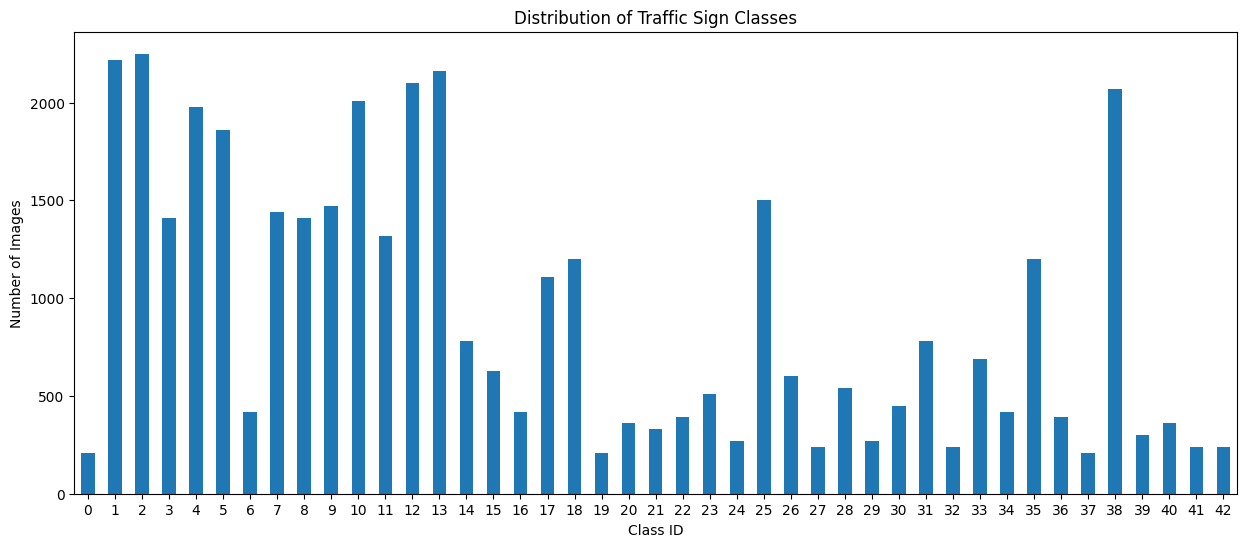

In [16]:
plt.figure(figsize=(15, 6))

class_counts.plot(kind='bar')

plt.title('Distribution of Traffic Sign Classes')
plt.xlabel('Class ID')
plt.ylabel('Number of Images')
plt.xticks(rotation=0)
plt.show()

## 7.3 Image Dimensions Analysis

Analyze the width and height of traffic sign images to understand the variations in image dimensions. This analysis helps determine whether image resizing is required during preprocessing.

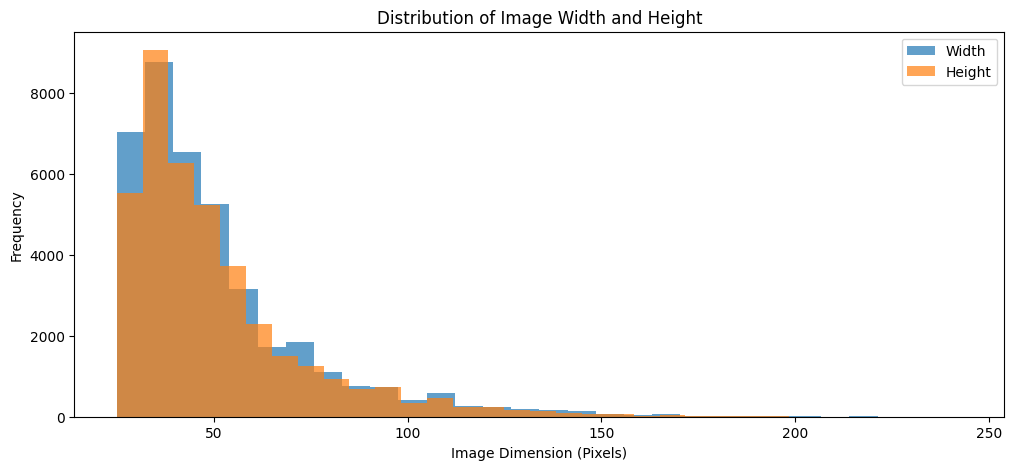

In [17]:
plt.figure(figsize=(12, 5))

plt.hist(train_df['Width'], bins=30, alpha=0.7, label='Width')
plt.hist(train_df['Height'], bins=30, alpha=0.7, label='Height')

plt.title('Distribution of Image Width and Height')
plt.xlabel('Image Dimension (Pixels)')
plt.ylabel('Frequency')
plt.legend()
plt.show()

## 7.4 Sample Traffic Sign Images Visualization

Visualize sample traffic sign images from different classes to understand their visual characteristics, shapes, colors, and patterns. This helps in understanding the image data before applying preprocessing techniques.

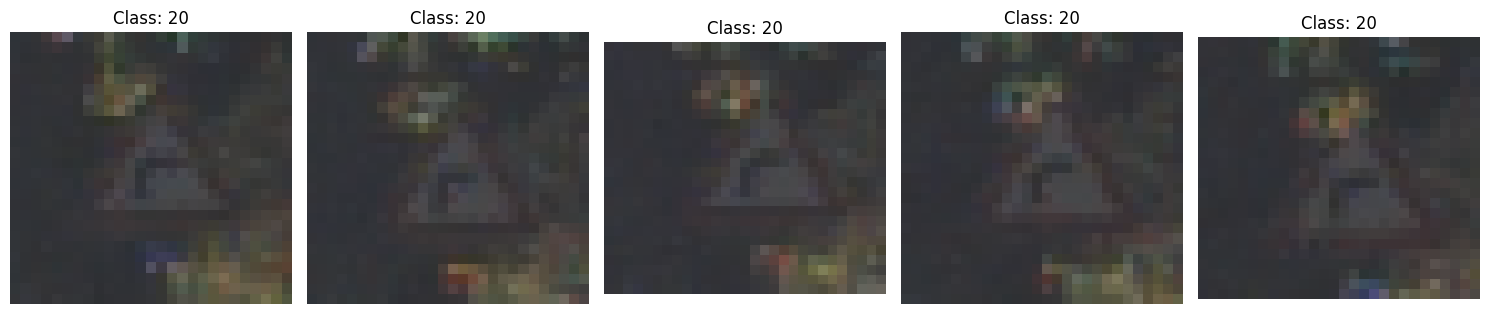

In [18]:
import matplotlib.pyplot as plt
import cv2
import os

plt.figure(figsize=(15, 5))

for i in range(5):
    img_path = os.path.join(data_dir, train_df.iloc[i]['Path'])
    image = cv2.imread(img_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.subplot(1, 5, i + 1)
    plt.imshow(image)
    plt.title(f"Class: {train_df.iloc[i]['ClassId']}")
    plt.axis('off')

plt.tight_layout()
plt.show()

## 7.5 Class-wise Image Visualization

Visualize sample images from different traffic sign classes to compare their visual features. This helps understand the differences in shapes, colors, and patterns across traffic sign categories.

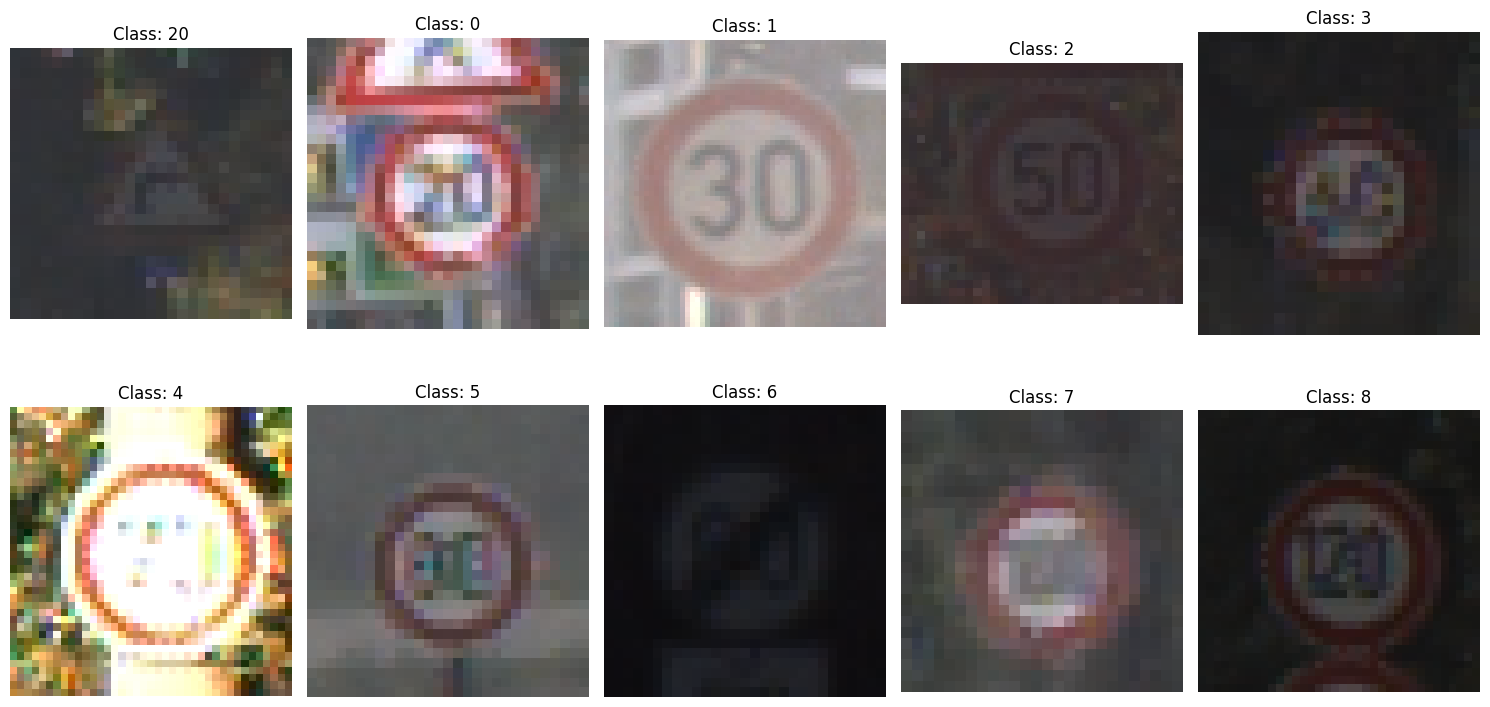

In [19]:
plt.figure(figsize=(15, 8))

sample_classes = train_df['ClassId'].unique()[:10]

for i, class_id in enumerate(sample_classes):
    img_path = train_df[train_df['ClassId'] == class_id]['Path'].iloc[0]
    full_path = os.path.join(data_dir, img_path)

    image = cv2.imread(full_path)

    if image is not None:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        plt.subplot(2, 5, i + 1)
        plt.imshow(image)
        plt.title(f"Class: {class_id}")
        plt.axis('off')

plt.tight_layout()
plt.show()

## 7.6 Region of Interest (ROI) Analysis

Analyze the Region of Interest (ROI) coordinates available in the dataset. These coordinates represent the specific area of the image containing the traffic sign. This analysis helps understand the sign region within each image.

In [20]:
roi_columns = ['Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2']

display(train_df[roi_columns].describe())

,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2
count,39209.000000,39209.000000,39209.000000,39209.000000
mean,5.999515,5.962381,45.197302,44.728379
std,1.475493,1.385440,23.060157,21.971145
min,0.000000,5.000000,20.000000,20.000000
25%,5.000000,5.000000,29.000000,30.000000
50%,6.000000,6.000000,38.000000,38.000000
75%,6.000000,6.000000,53.000000,52.000000
max,20.000000,20.000000,223.000000,205.000000


**Observation:**
- All 39,209 training records contain ROI coordinates.
- The average top-left coordinates (X1, Y1) are approximately (6, 6).
- The average bottom-right coordinates (X2, Y2) are approximately (45, 45).
- ROI coordinates vary across images, indicating differences in the traffic sign region and image dimensions.
- These coordinates can be used to extract the traffic sign region during image preprocessing.

## 7.7 Region of Interest (ROI) Visualization

Visualize the Region of Interest (ROI) on sample traffic sign images using the provided bounding box coordinates. This helps understand how the traffic sign region is located within each image.

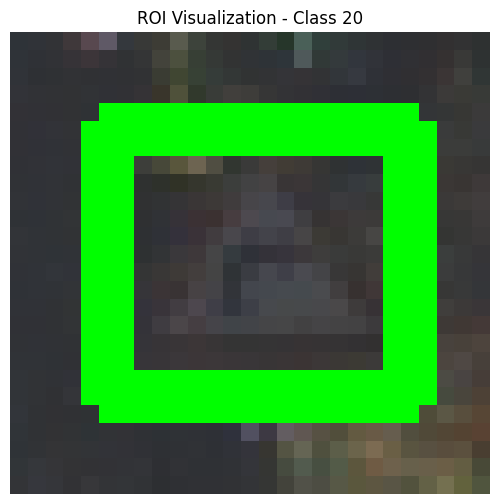

In [21]:
plt.figure(figsize=(8, 6))

sample = train_df.iloc[0]

img_path = os.path.join(data_dir, sample['Path'])
image = cv2.imread(img_path)

if image is not None:
    x1 = sample['Roi.X1']
    y1 = sample['Roi.Y1']
    x2 = sample['Roi.X2']
    y2 = sample['Roi.Y2']

    cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.imshow(image)
    plt.title(f"ROI Visualization - Class {sample['ClassId']}")
    plt.axis('off')
    plt.show()

## 7.8 Image Channel Analysis

Analyze the color channels of sample traffic sign images to understand their visual color information. This helps determine the image format required for the preprocessing stage.

Image Shape: (26, 27, 3)
Number of Color Channels: 3


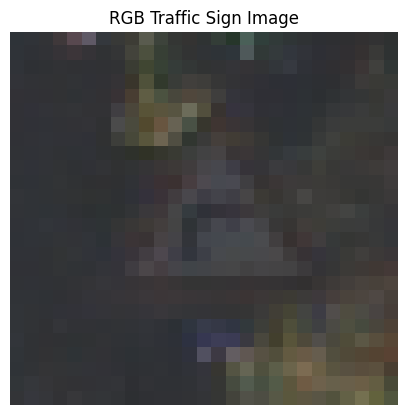

In [22]:
sample_path = os.path.join(data_dir, train_df.iloc[0]['Path'])

image = cv2.imread(sample_path)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

print("Image Shape:", image_rgb.shape)
print("Number of Color Channels:", image_rgb.shape[2])

plt.figure(figsize=(5, 5))
plt.imshow(image_rgb)
plt.title("RGB Traffic Sign Image")
plt.axis('off')
plt.show()

## 7.9 Class-wise Image Dimensions Analysis

Analyze the average width and height of images across different traffic sign classes. This helps understand the variations in image dimensions among the classes and supports decisions during image preprocessing.

In [23]:
class_dimensions = train_df.groupby('ClassId')[['Width', 'Height']].mean()

display(class_dimensions)

,Width,Height
ClassId,,
0,52.909524,53.857143
1,52.484685,53.500901
2,46.089333,46.183111
3,44.787234,45.687234
4,45.919697,46.272727
5,42.515054,42.823656
6,40.404762,42.126190
7,44.087500,44.672917
8,43.344681,43.428369


**Observation:**
- The average image dimensions vary across different traffic sign classes.
- Class 0 has an average width of approximately 52.91 pixels and height of 53.86 pixels.
- Class 23 has the highest average width of approximately 65.45 pixels.
- Class 14 has the highest average height of approximately 66.43 pixels.
- These variations indicate that image resizing is required during preprocessing to maintain a consistent input size.

## 7.10 Class-wise Image Dimensions Visualization

Visualize the average width and height of images across different traffic sign classes using a line chart. This helps compare image dimension variations among the classes.

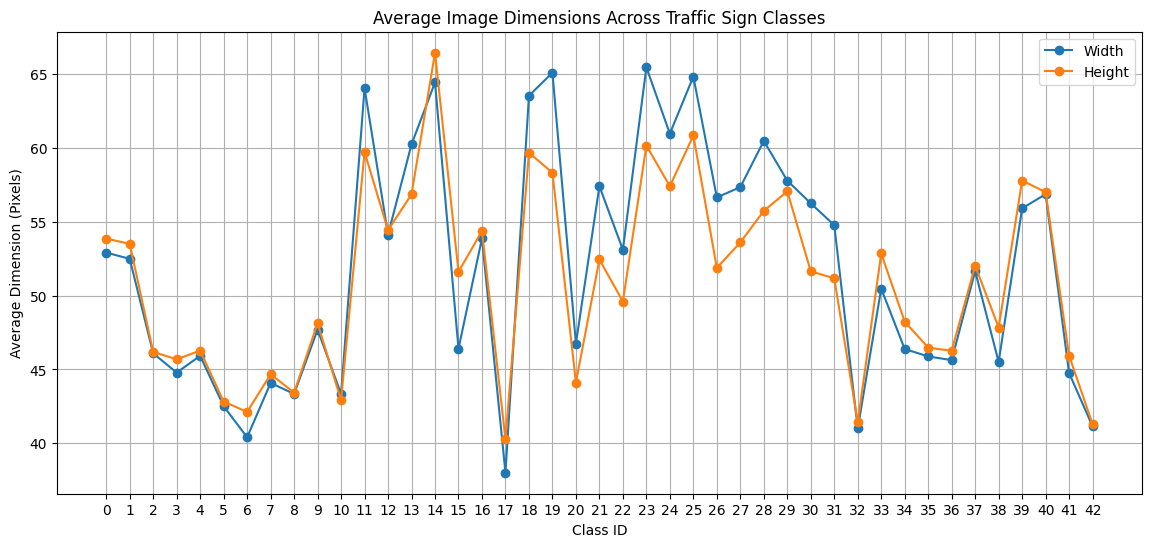

In [24]:
plt.figure(figsize=(14, 6))

plt.plot(class_dimensions.index, class_dimensions['Width'], marker='o', label='Width')
plt.plot(class_dimensions.index, class_dimensions['Height'], marker='o', label='Height')

plt.title('Average Image Dimensions Across Traffic Sign Classes')
plt.xlabel('Class ID')
plt.ylabel('Average Dimension (Pixels)')
plt.xticks(range(43))
plt.legend()
plt.grid()
plt.show()

# 8. Data Preprocessing

Data preprocessing involves preparing the traffic sign images for model training. It includes loading images, extracting the required image regions, resizing images to a consistent dimension, and preparing the data for model development.

## 8.1 Image Loading and ROI Cropping

Load the traffic sign images using their file paths and extract the Region of Interest (ROI) using the available bounding coordinates. This helps focus on the traffic sign region and removes unnecessary background areas.

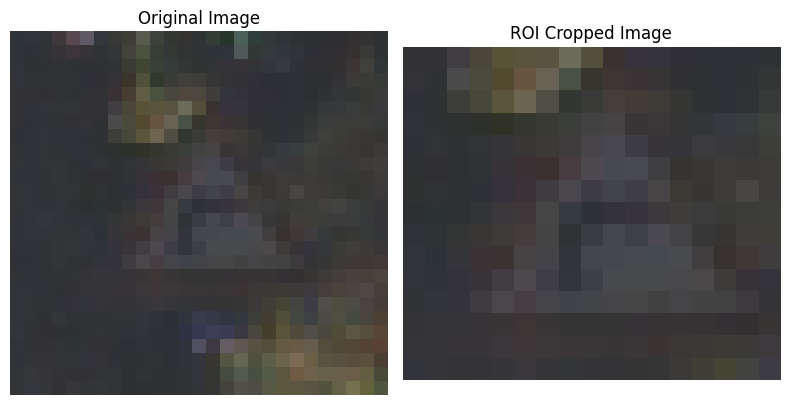

In [25]:
import cv2
import os

sample = train_df.iloc[0]

img_path = os.path.join(data_dir, sample['Path'])
image = cv2.imread(img_path)

x1 = int(sample['Roi.X1'])
y1 = int(sample['Roi.Y1'])
x2 = int(sample['Roi.X2'])
y2 = int(sample['Roi.Y2'])

cropped_image = image[y1:y2, x1:x2]

cropped_image = cv2.cvtColor(cropped_image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cropped_image)
plt.title("ROI Cropped Image")
plt.axis('off')

plt.tight_layout()
plt.show()

## 8.2 Image Resizing

Resize all cropped traffic sign images to a fixed dimension of 32 × 32 pixels. This ensures that all images have a consistent input size for CNN model training.

Original Cropped Image Shape: (15, 17, 3)
Resized Image Shape: (32, 32, 3)


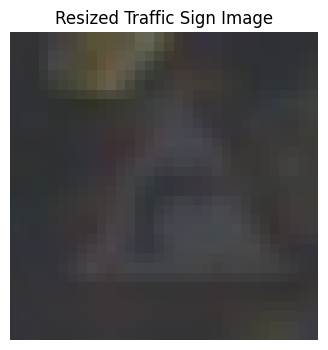

In [26]:
IMG_SIZE = 32

resized_image = cv2.resize(cropped_image, (IMG_SIZE, IMG_SIZE))

print("Original Cropped Image Shape:", cropped_image.shape)
print("Resized Image Shape:", resized_image.shape)

plt.figure(figsize=(4, 4))
plt.imshow(resized_image)
plt.title("Resized Traffic Sign Image")
plt.axis('off')
plt.show()

## 8.3 Image Normalization

Normalize the pixel values of the resized traffic sign images by scaling them from the range of 0–255 to 0–1. This helps improve the stability and efficiency of CNN model training.

In [27]:
normalized_image = resized_image / 255.0

print("Minimum Pixel Value:", normalized_image.min())
print("Maximum Pixel Value:", normalized_image.max())
print("Normalized Image Shape:", normalized_image.shape)

Minimum Pixel Value: 0.14901960784313725
Maximum Pixel Value: 0.41568627450980394
Normalized Image Shape: (32, 32, 3)


## 8.4 Prepare Training Images

Apply ROI cropping, image resizing, and pixel normalization to all training images. Store the processed images and their corresponding class labels for CNN model training.

In [28]:
IMG_SIZE = 32

X_train = []
y_train = []

for _, row in train_df.iterrows():
    img_path = os.path.join(data_dir, row['Path'])
    image = cv2.imread(img_path)

    if image is not None:
        x1 = int(row['Roi.X1'])
        y1 = int(row['Roi.Y1'])
        x2 = int(row['Roi.X2'])
        y2 = int(row['Roi.Y2'])

        cropped = image[y1:y2, x1:x2]

        if cropped.size > 0:
            resized = cv2.resize(cropped, (IMG_SIZE, IMG_SIZE))
            normalized = resized / 255.0

            X_train.append(normalized)
            y_train.append(row['ClassId'])

X_train = np.array(X_train, dtype=np.float32)
y_train = np.array(y_train, dtype=np.int64)

print("Training Images Shape:", X_train.shape)
print("Training Labels Shape:", y_train.shape)

Training Images Shape: (39209, 32, 32, 3)
Training Labels Shape: (39209,)


In [29]:
print("Total Training Records:", len(train_df))
print("Processed Images:", len(X_train))
print("Skipped Images:", len(train_df) - len(X_train))

Total Training Records: 39209
Processed Images: 39209
Skipped Images: 0


## 8.5 Prepare Test Images

Apply ROI cropping, image resizing, and pixel normalization to all test images. Store the processed test images and their corresponding class labels for model evaluation.

In [30]:
X_test = []
y_test = []

test_image_dir = os.path.join(data_dir, "Test", "Test")

for _, row in test_df.iterrows():
    img_path = os.path.join(data_dir, row['Path'])
    img_path = img_path.replace(
        os.path.join(data_dir, "Test"),
        test_image_dir
    )

    image = cv2.imread(img_path)

    if image is not None:
        x1 = int(row['Roi.X1'])
        y1 = int(row['Roi.Y1'])
        x2 = int(row['Roi.X2'])
        y2 = int(row['Roi.Y2'])

        cropped = image[y1:y2, x1:x2]

        if cropped.size > 0:
            resized = cv2.resize(cropped, (IMG_SIZE, IMG_SIZE))
            normalized = resized / 255.0

            X_test.append(normalized)
            y_test.append(row['ClassId'])

X_test = np.array(X_test, dtype=np.float32)
y_test = np.array(y_test, dtype=np.int64)

print("Test Images Shape:", X_test.shape)
print("Test Labels Shape:", y_test.shape)
print("Processed Test Images:", len(X_test))
print("Skipped Test Images:", len(test_df) - len(X_test))

Test Images Shape: (12630, 32, 32, 3)
Test Labels Shape: (12630,)
Processed Test Images: 12630
Skipped Test Images: 0


## 8.6 Preprocessed Dataset Verification

Verify the shapes, data types, and pixel value ranges of the preprocessed training and testing datasets before proceeding with CNN model development.

In [31]:
print("Training Data Shape:", X_train.shape)
print("Training Labels Shape:", y_train.shape)

print("Testing Data Shape:", X_test.shape)
print("Testing Labels Shape:", y_test.shape)

print("\nTraining Pixel Range:", X_train.min(), "to", X_train.max())
print("Testing Pixel Range:", X_test.min(), "to", X_test.max())

print("\nTraining Data Type:", X_train.dtype)
print("Testing Data Type:", X_test.dtype)

Training Data Shape: (39209, 32, 32, 3)
Training Labels Shape: (39209,)
Testing Data Shape: (12630, 32, 32, 3)
Testing Labels Shape: (12630,)

Training Pixel Range: 0.0 to 1.0
Testing Pixel Range: 0.0 to 1.0

Training Data Type: float32
Testing Data Type: float32


# 9. CNN Model Development

Develop a Convolutional Neural Network (CNN) model to learn visual features from traffic sign images and classify them into their corresponding categories.

## 9.1 Import Deep Learning Libraries


In [32]:
#Import deep learning libraries
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.utils import to_categorical

## 9.2 Training and Validation Split

Split the training dataset into training and validation sets. Use stratified sampling to maintain the class distribution across both sets.

In [33]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training Images:", X_train.shape)
print("Training Labels:", y_train.shape)

print("Validation Images:", X_val.shape)
print("Validation Labels:", y_val.shape)

Training Images: (31367, 32, 32, 3)
Training Labels: (31367,)
Validation Images: (7842, 32, 32, 3)
Validation Labels: (7842,)


## 9.3 Handling Class Imbalance Using Class Weights

The dataset contains an imbalance in the number of images across different traffic sign classes. To handle this issue, class weights are calculated using the training data.

Class weights help the CNN model give more importance to underrepresented classes during training, improving its ability to learn from all classes.

In [34]:
# Calculate Class Weights

from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train)

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, class_weights))

print("Class Weights:")
print(class_weights)

Class Weights:
{np.int64(0): np.float64(4.342054263565892), np.int64(1): np.float64(0.41073486276974647), np.int64(2): np.float64(0.40525839793281654), np.int64(3): np.float64(0.6466889328715157), np.int64(4): np.float64(0.460520906741837), np.int64(5): np.float64(0.4902319329832458), np.int64(6): np.float64(2.171027131782946), np.int64(7): np.float64(0.6332162467700259), np.int64(8): np.float64(0.6466889328715157), np.int64(9): np.float64(0.6202934662236987), np.int64(10): np.float64(0.4536474603725558), np.int64(11): np.float64(0.6907813601127555), np.int64(12): np.float64(0.43420542635658915), np.int64(13): np.float64(0.4221441645133506), np.int64(14): np.float64(1.169014609421586), np.int64(15): np.float64(1.4473514211886305), np.int64(16): np.float64(2.171027131782946), np.int64(17): np.float64(0.8214697255394929), np.int64(18): np.float64(0.759859496124031), np.int64(19): np.float64(4.342054263565892), np.int64(20): np.float64(2.5328649870801034), np.int64(21): np.float64(2.76312

## 9.4 Build CNN Architecture

Build a Convolutional Neural Network (CNN) using convolution, max-pooling, flattening, and dense layers to extract image features and classify traffic signs into 43 categories.

In [35]:
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation='relu'),
    Dropout(0.5),

    Dense(43, activation='softmax')
])

C:\Users\Gowtham G\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


## 9.5 Compile CNN Model

Compile the CNN model using the Adam optimizer, sparse categorical crossentropy loss function, and accuracy metric.

In [36]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

## 9.6 CNN Model Summary

Display the CNN model architecture, including the layers, output shapes, and number of trainable parameters.

In [37]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 30, 30, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 15, 15, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 13, 13, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 6, 6, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 2304)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         295,040 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 43)                  │           5,547 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 319,979 (1.22 MB)

 Trainable params: 319,979 (1.22 MB)

 Non-trainable params: 0 (0.00 B)

## 9.7 Train CNN Model

Train the CNN model using the training dataset and the calculated class weights and validate its performance using the validation dataset. Monitor training and validation accuracy and loss across epochs.

In [38]:
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=64,
    class_weight=class_weights
)

Epoch 1/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 15s 25ms/step - accuracy: 0.5313 - loss: 1.6631 - val_accuracy: 0.9222 - val_loss: 0.4234
Epoch 2/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 12s 24ms/step - accuracy: 0.8569 - loss: 0.4456 - val_accuracy: 0.9651 - val_loss: 0.1949
Epoch 3/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - accuracy: 0.9083 - loss: 0.2712 - val_accuracy: 0.9746 - val_loss: 0.1234
Epoch 4/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - accuracy: 0.9314 - loss: 0.1975 - val_accuracy: 0.9792 - val_loss: 0.0928
Epoch 5/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 14s 29ms/step - accuracy: 0.9475 - loss: 0.1479 - val_accuracy: 0.9853 - val_loss: 0.0727
Epoch 6/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 12s 25ms/step - accuracy: 0.9542 - loss: 0.1291 - val_accuracy: 0.9865 - val_loss: 0.0613
Epoch 7/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 12s 24ms/step - accuracy: 0.9610 - loss: 0.1055 - val_accuracy: 0.9880 - val_loss: 0.0600
Epoch 8/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 11s 23ms/step - accuracy: 0.9658 - loss: 0.0938 - 

## 9.8 Training and Validation Performance Visualization

Visualize the training and validation accuracy and loss over the epochs to understand the CNN model's learning performance.

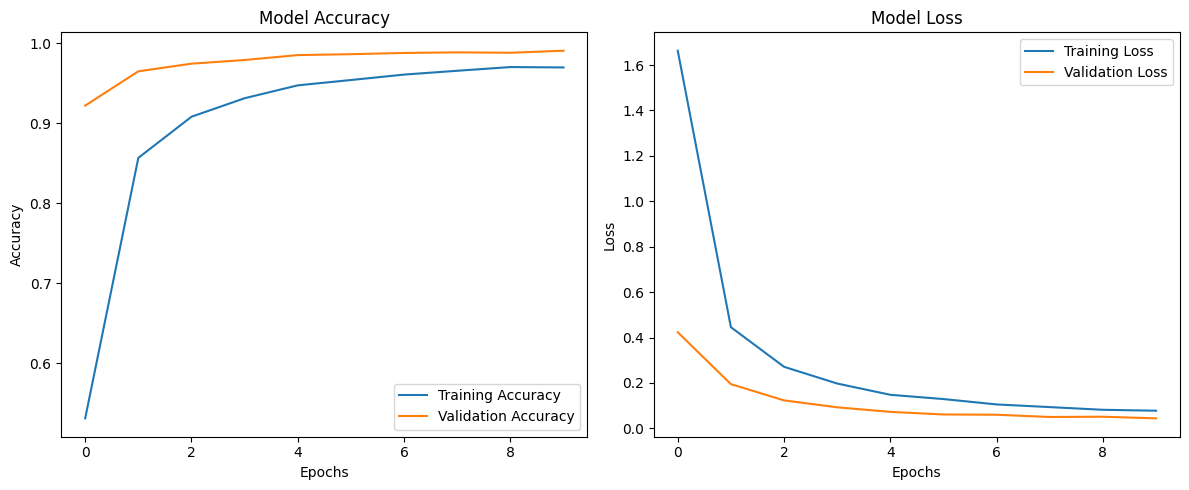

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

## 9.9 CNN Model Evaluation

Evaluate the trained CNN model using the test dataset to measure its performance on unseen traffic sign images.

In [40]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", test_accuracy * 100)

395/395 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9637 - loss: 0.1501
Test Loss: 0.1501149833202362
Test Accuracy: 0.9636579751968384
Test Accuracy (%): 96.36579751968384


## 9.10 Classification Report

Generate a classification report to evaluate the CNN model using precision, recall, and F1-score for each traffic sign class.

In [41]:
from sklearn.metrics import classification_report

y_pred_prob = model.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)

print(classification_report(y_test, y_pred))

395/395 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
              precision    recall  f1-score   support

           0       1.00      0.98      0.99        60
           1       0.96      0.98      0.97       720
           2       0.97      0.97      0.97       750
           3       0.93      0.95      0.94       450
           4       0.99      0.95      0.97       660
           5       0.91      0.96      0.93       630
           6       1.00      0.84      0.91       150
           7       0.98      0.91      0.95       450
           8       0.97      0.96      0.96       450
           9       0.98      1.00      0.99       480
          10       0.99      0.98      0.99       660
          11       0.97      0.93      0.95       420
          12       0.99      0.99      0.99       690
          13       0.99      1.00      1.00       720
          14       1.00      1.00      1.00       270
          15       0.99      1.00      1.00       210
          16       1.00      0.98      0

## 9.11 Confusion Matrix

Generate a confusion matrix to visualize the classification performance of the CNN model and identify misclassified traffic sign images across different classes.

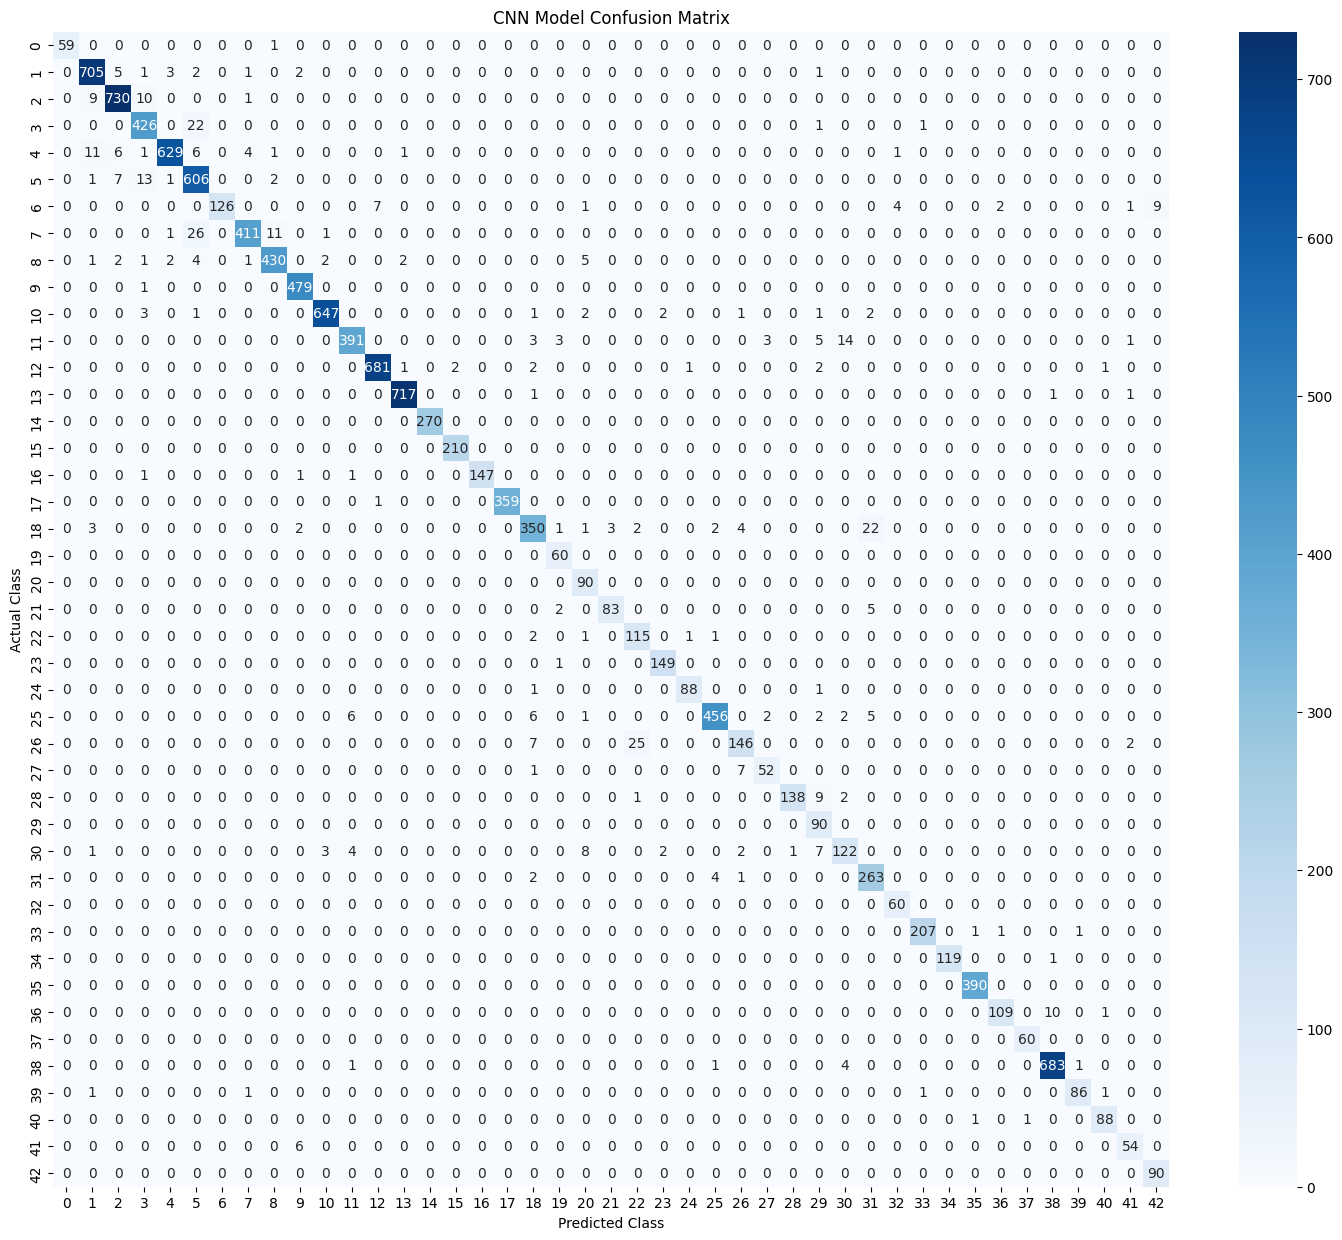

In [42]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(18, 15))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('CNN Model Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.show()

### 9.11.1 Class-wise Error Analysis

Calculate the number of correct and incorrect predictions and the error rate for each class.


In [43]:
# Recalculate Confusion Matrix and Misclassification Analysis

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=np.arange(43))

misclassified_classes = []

for i in range(43):
    total = np.sum(cm[i])
    correct = cm[i, i]
    incorrect = total - correct

    error_rate = (incorrect / total) * 100 if total > 0 else 0

    misclassified_classes.append({
        'Class': i,
        'Total Images': total,
        'Correct Predictions': correct,
        'Incorrect Predictions': incorrect,
        'Error Rate (%)': round(error_rate, 2)
    })

misclassified_df = pd.DataFrame(misclassified_classes)

misclassified_df = misclassified_df.sort_values(
    by='Error Rate (%)',
    ascending=False
)

display(misclassified_df.reset_index(drop=True))

,Class,Total Images,Correct Predictions,Incorrect Predictions,Error Rate (%)
0,26,180,146,34,18.89
1,30,150,122,28,18.67
2,6,150,126,24,16.00
3,27,60,52,8,13.33
4,18,390,350,40,10.26
5,41,60,54,6,10.00
6,36,120,109,11,9.17
7,7,450,411,39,8.67
8,28,150,138,12,8.00
9,21,90,83,7,7.78


### 9.11.2 Top 10 Misclassified Class Pairs

Identify the pairs of classes that the model confuses most often.


In [44]:
# Identify Top 10 Misclassified Class Pairs

confusion_pairs = []

for actual in range(43):
    for predicted in range(43):
        if actual != predicted and cm[actual, predicted] > 0:
            confusion_pairs.append({
                'Actual Class': actual,
                'Predicted Class': predicted,
                'Misclassified Images': cm[actual, predicted]
            })

confusion_pairs_df = pd.DataFrame(confusion_pairs)

confusion_pairs_df = confusion_pairs_df.sort_values(
    by='Misclassified Images',
    ascending=False
)

display(confusion_pairs_df.head(10).reset_index(drop=True))

,Actual Class,Predicted Class,Misclassified Images
0,7,5,26
1,26,22,25
2,18,31,22
3,3,5,22
4,11,30,14
5,5,3,13
6,7,8,11
7,4,1,11
8,2,3,10
9,36,38,10


**Observation:**
- The CNN model performs well across most traffic sign classes, with an overall test accuracy of 96.37%.
- Class weights were used to handle class imbalance. Several rare classes now have a recall of 1.00 (for example, Class 19, 20, 29, 32 and 37), but the precision of a few of them is lower (Class 29 has 0.76, Class 22 has 0.80 and Class 20 has 0.83) because the model predicts these classes more often.
- Some classes still show a high error rate, particularly Class 26 (18.89%), Class 30 (18.67%) and Class 6 (16.00%).
- The most frequent confusions are Class 7 predicted as 5, Class 26 predicted as 22, Class 18 predicted as 31 and Class 3 predicted as 5. These are visually similar signs.
- Further improvements can be explored through data augmentation, hyperparameter tuning and early stopping.


## 9.12 Actual vs Predicted Image Visualization

Visualize sample test images along with their actual and predicted class labels to evaluate the CNN model's prediction performance.

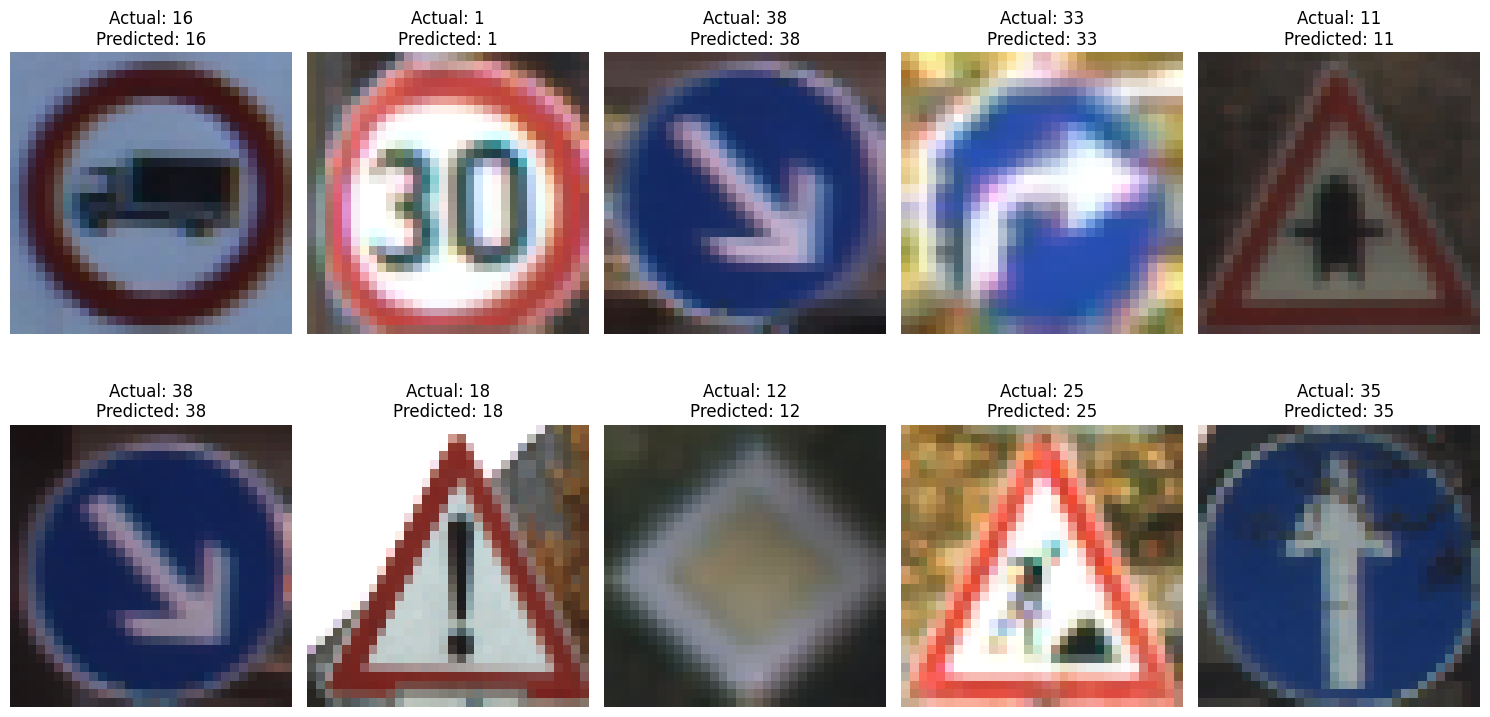

In [45]:
plt.figure(figsize=(15, 8))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    # Images were loaded with OpenCV (BGR), so convert to RGB only for display
    plt.imshow(cv2.cvtColor(X_test[i], cv2.COLOR_BGR2RGB))

    actual = y_test[i]
    predicted = y_pred[i]

    plt.title(f"Actual: {actual}\nPredicted: {predicted}")
    plt.axis('off')

plt.tight_layout()
plt.show()

## 9.13 Save Trained CNN Model

Save the trained CNN model in Keras (.keras) format for future predictions and reuse.

In [46]:
model.save(os.path.join(data_dir, "traffic_sign_cnn_model.keras"))

print("CNN Model saved successfully!")

CNN Model saved successfully!


# 10. Model Loading and Prediction Verification


## 10.1 Load Saved Model and Predict a Sample Image

Load the saved CNN model and perform a sample prediction to verify that it can be reused.


In [47]:
loaded_model = tf.keras.models.load_model(
    os.path.join(data_dir, "traffic_sign_cnn_model.keras")
)

sample_image = X_test[0:1]

prediction = loaded_model.predict(sample_image)

predicted_class = np.argmax(prediction, axis=1)[0]
actual_class = y_test[0]

print("Actual Class:", actual_class)
print("Predicted Class:", predicted_class)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step
Actual Class: 16
Predicted Class: 16


## 10.2 Verify Loaded Model Performance

Evaluate the loaded model on the test dataset to confirm that it gives the same accuracy as the trained model.


In [48]:
# Load and Verify the Saved Model

from tensorflow.keras.models import load_model

loaded_model = load_model(os.path.join(data_dir, "traffic_sign_cnn_model.keras"))

test_loss, test_accuracy = loaded_model.evaluate(X_test, y_test)

print("Loaded Model Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Loaded Model Test Loss:", round(test_loss, 4))

395/395 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9637 - loss: 0.1501
Loaded Model Test Accuracy: 96.37 %
Loaded Model Test Loss: 0.1501


# 11. Project Conclusion

In this project, a Convolutional Neural Network (CNN) was developed to classify traffic signs into 43 different categories.

The model was trained and evaluated using the GTSRB traffic sign dataset. Image preprocessing, ROI cropping, resizing, normalization, and class-weight handling were applied.

The final model achieved a test accuracy of **96.37%**.

The results demonstrate that CNNs can effectively learn visual features and classify traffic signs. Further improvements can be explored through data augmentation and hyperparameter tuning.